In [1]:
## Instalasi Library
%%capture
!pip install pandas missingno numpy matplotlib seaborn scipy

In [1]:
## Load library
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from scipy import stats

In [2]:
## Load Dataset
dataset = pd.read_csv('datasets/diabetes_prediction_dataset.csv')

In [3]:
## Mengetahui Ukuran Dataset (baris dan kolom)
dataset.shape

(100000, 9)

In [4]:
# lima contoh record data
dataset.head(5) 

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [5]:
## Menampilkan Nama Kolom
dataset.columns

Index(['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history',
       'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes'],
      dtype='object')

In [6]:
# menampilkan ringkasan informasi dataset
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               99998 non-null   object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


In [7]:
numerical_column = dataset.select_dtypes(include='number').columns
numerical_column.tolist()
numerical_column

Index(['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level',
       'blood_glucose_level', 'diabetes'],
      dtype='object')

In [8]:
print(type(numerical_column))
print(type(numerical_column.tolist()))

<class 'pandas.core.indexes.base.Index'>
<class 'list'>


In [9]:
categorical_column = dataset.select_dtypes(exclude='number').columns
categorical_column.tolist()
categorical_column

Index(['gender', 'smoking_history'], dtype='object')

In [10]:
dataset.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [11]:
## Mendapatkan statistik untuk non-numerical / categorical value:
dataset.describe(include=["object", "bool"])

,gender,smoking_history
count,99998,100000
unique,3,6
top,Female,No Info
freq,58551,35816


<Axes: ylabel='Frequency'>

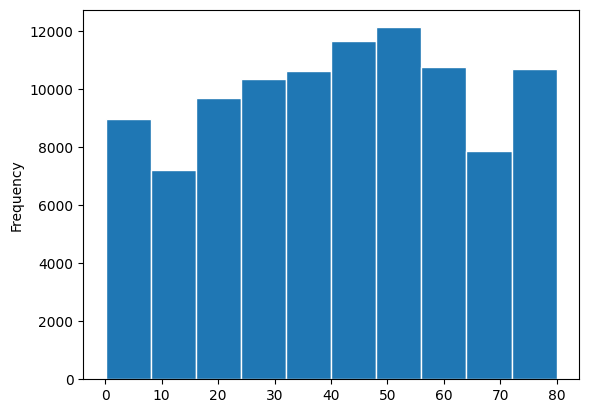

In [12]:
## Distribusi kolom dalam dataset
dataset['age'].plot(kind='hist', edgecolor='white')

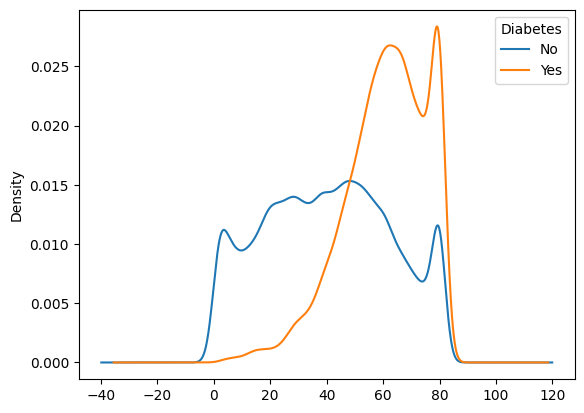

In [13]:
dataset.groupby('diabetes')['age'].plot(kind='kde')
plt.legend(['No', 'Yes'], loc='upper right', title='Diabetes')

<Axes: >

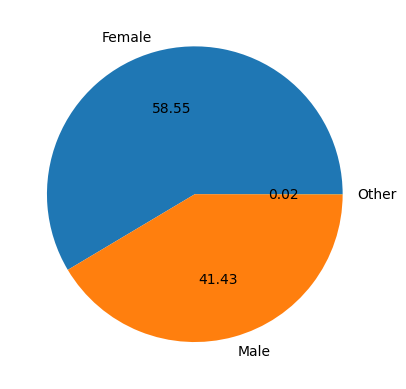

In [14]:
dataset.groupby('gender').size().plot(kind='pie', autopct='%.2f')

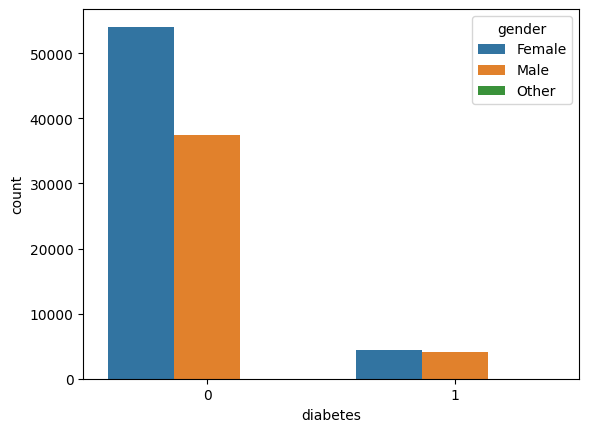

In [15]:
p = sns.countplot(data=dataset, x='diabetes', hue='gender')

In [18]:
missing_values = dataset.isnull().sum()
missing_values

gender                 2
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

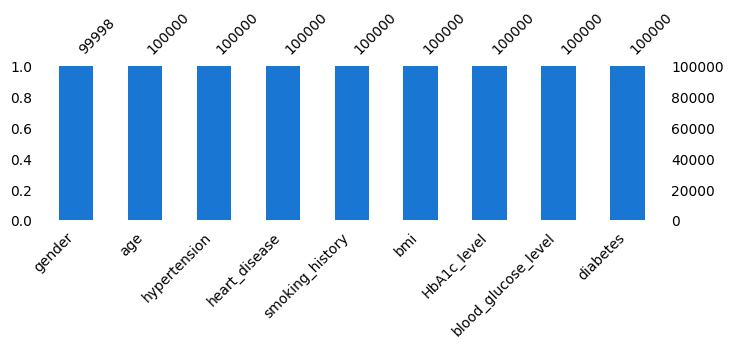

In [19]:
## Mencari Missing Value (dengan chart)
msno.bar(dataset, figsize = (8,2),color = "#1976D2", fontsize=10)
plt.show()

In [21]:
## Melihat Unique Value pada tiap kolom
for column_name in dataset.columns:
    
    unique_values = len(dataset[column_name].unique())
    print('''Kolom '{column_name}' memiliki
    '{unique_values}' unique values'''.format(
    column_name=column_name, unique_values=unique_values))

Kolom 'gender' memiliki
    '4' unique values
Kolom 'age' memiliki
    '102' unique values
Kolom 'hypertension' memiliki
    '2' unique values
Kolom 'heart_disease' memiliki
    '2' unique values
Kolom 'smoking_history' memiliki
    '6' unique values
Kolom 'bmi' memiliki
    '4247' unique values
Kolom 'HbA1c_level' memiliki
    '18' unique values
Kolom 'blood_glucose_level' memiliki
    '18' unique values
Kolom 'diabetes' memiliki
    '2' unique values


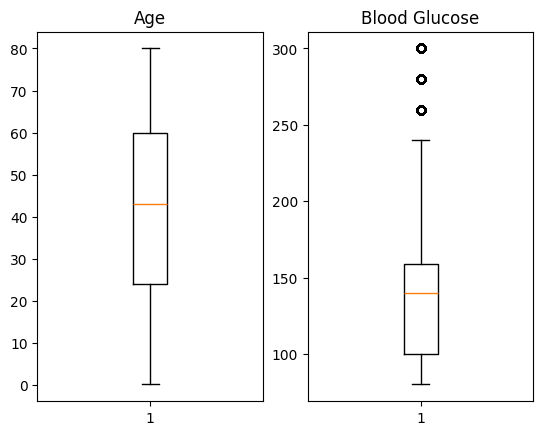

In [22]:
## Mencari outliers pada dataset
plt.subplot(1, 2, 1)
plt.title("Age")
plt.boxplot(dataset['age'])
plt.subplot(1, 2, 2)
plt.title("Blood Glucose")
plt.boxplot(dataset['blood_glucose_level'])
plt.show()

<Axes: >

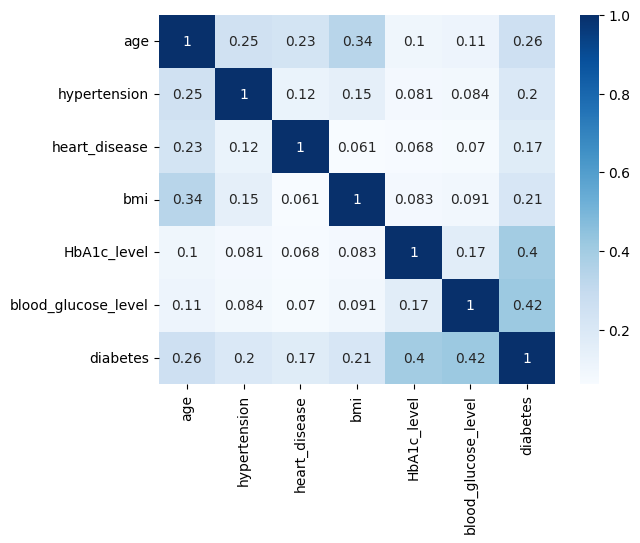

In [23]:
## Melihat Korelasi Antar Kolom dengan Kolom diabetes
# calculate the correlation matrix on the numeric columns
corr = dataset.select_dtypes('number').corr()
# plot the heatmap
sns.heatmap(corr, cmap="Blues", annot=True)